# Importaciones de las rutas y librerías
## Aqui importamos las librerías necesarias así como la extracción de los csv utilizados

In [ ]:
import pandas as pd
import os

os.chdir(r'C:\Users\balca\OneDrive\Desktop\Personal\Cursos\ml-course\workspace\notebooks\homeworks\data\tarea1')
estudiantes = pd.read_csv('data_studentlist.csv', header='infer')
estudiantes.head(10)

In [ ]:
# 1) Altura promedio de los estudiantes varones:

altura_promedio_h = estudiantes.loc[estudiantes["Gender"]=="M", "Height"].mean()
print(altura_promedio_h)

In [ ]:
# 2) Altura promedio de las estudiantes
altura_promedio_m = estudiantes.loc[estudiantes["Gender"]=="F", "Height"].mean()
print(altura_promedio_m)

In [ ]:
# 3) Peso promedio de los estudiantes varones:
peso_promedio_h = estudiantes.loc[estudiantes["Gender"] == "M", "Weight"].mean()
print(peso_promedio_h)

In [ ]:
# 4) Peso promedio de las estudiantes:
peso_promedio_m = estudiantes.loc[estudiantes["Gender"] == "F", "Weight"].mean()
print(peso_promedio_m)

In [ ]:
# 5) La mayor estatura entre los estudiantes varones
mayor_estatura_h = estudiantes.loc[estudiantes["Gender"] == "M", "Height"].max()
print(mayor_estatura_h)

In [ ]:
# 6) La menor estatura entre las estudiantes:
menor_estatura_m = estudiantes.loc[estudiantes["Gender"] == "F", "Height"].min()
print(menor_estatura_m)

In [ ]:
# 7) El peso más ligero entre los estudiantes varones de estatura superior a 1.75 m:
peso_mas_ligero_h = estudiantes.loc[(estudiantes["Gender"] == "M") & (estudiantes["Height"]>175), "Weight"].min()
print(peso_mas_ligero_h)

In [ ]:
# 8) El mayor peso entre las estudiantes de estatura inferior a 1.60 m
peso_mayor_estatura_m = estudiantes.loc[(estudiantes["Gender"] == "F") & (estudiantes["Height"]<160), "Weight"].max()
print(peso_mayor_estatura_m)

In [ ]:
# 9) La nota promedio de los alumnos (hombres y mujeres) sin ausencias ('N'):
nota_promedio_alumnos = estudiantes.loc[estudiantes["Absence"] == "N", "Grade"].mean()
print(nota_promedio_alumnos)

In [ ]:
# 10) La nota promedio de los alumnos (hombres y mujeres) con absentismo ('Y'):
nota_promedio_alumnos_abst = estudiantes.loc[estudiantes["Absence"] == "Y", "Grade"].mean()
print(nota_promedio_alumnos_abst)

In [ ]:
#11) Altura promedio de los alumnos (hombres y mujeres) con grupo sanguíneo 'A' o 'AB':
altura_promedio_alumnos = estudiantes.loc[(estudiantes["Bloodtype"] == "A") | (estudiantes["Bloodtype"] == "AB"), "Height" ].mean()
print(altura_promedio_alumnos)

In [ ]:
# 12) Altura promedio de los alumnos varones con grupo sanguíneo 'A' o 'AB
altura_promedio_alumnos_m = estudiantes.loc[(estudiantes["Gender"] == "M") & ((estudiantes["Bloodtype"] == "A") | (estudiantes["Bloodtype"] == "AB")), "Height" ].mean()
print(altura_promedio_alumnos_m)

In [ ]:
# 13) Edad promedio de los alumnos (hombres y mujeres) con absentismo ('Y') cuya nota es mayor o igual a 3
edad_promedio = estudiantes.loc[(estudiantes["Absence"] == "Y")&(estudiantes["Grade"]>=3),"Age"].mean()
print(edad_promedio)

## Parte 2
# Importacion de librerías 
### Domicilios y censos pobalcionales 

In [ ]:
import pandas as pd
import numpy as np
import os
os.chdir(r'C:\Users\balca\OneDrive\Desktop\Personal\Cursos\ml-course\workspace\notebooks\homeworks\data\tarea1')
poblacion = pd.read_csv('data_census.csv', header='infer')
print(poblacion.shape)
poblacion.head(10)

In [ ]:
#Limpiamos los datos
#1) Primero quito los , para luego hacerlo enteros
poblacion["Population"] = poblacion["Population"].str.replace(",","",regex=False)
poblacion["Households"] = poblacion["Households"].str.replace(",","",regex=False)
#2) Lo convierto en numero
poblacion["Population"] = pd.to_numeric(poblacion["Population"])
#2) Lo convierto en numero
poblacion["Households"] = pd.to_numeric(poblacion["Households"])


In [ ]:
# 1) Población total con ProvinceCode igual a 115 o 116:
poblacion_total = poblacion.loc[poblacion["Province Code"].isin([115,116]), "Population"].sum()
print(poblacion_total)

In [ ]:
# 2) Población promedio de las ciudades donde hay más hombres (GenderRatio > 1)
poblacion_promedio = poblacion.loc[poblacion["Gender Ratio"] > 1, "Population"].mean()
print(poblacion_promedio)

In [ ]:
# 3) Lugares con más hombres (GenderRatio > 1) y menos de 2 personas por hogar:
lugares_con_mas_hombres = poblacion.loc[(poblacion["Gender Ratio"] > 1) & (poblacion["Person\'s Household"] < 2), "City Code"]
print(lugares_con_mas_hombres)

In [ ]:
# 4) Ordena el DataFrame en orden ascendente de 'Households' y muestra los 10 primeros
poblacion = poblacion.sort_values(["Households"], ascending=False)
poblacion.head(10)

## Parte 3
# Importacion de librerías 
### Domicilios y censos pobalcionales 

In [ ]:
import pandas as pd
import numpy as np
import os

os.chdir(r'C:\Users\balca\OneDrive\Desktop\Personal\Cursos\ml-course\workspace\notebooks\homeworks\data\tarea1')
ventas = pd.read_csv('data_sales.csv', header='infer')
print(ventas.shape)
ventas.head(5)


In [ ]:
# Convertimos el date en un tipo datetime
ventas.info()
ventas["Date"] = pd.to_datetime(ventas["Date"])


In [ ]:
# 1) Añade una nueva variable Amount = UnitPrice x Units y muestra las 5 primeras observaciones.
ventas["Amount"] = ventas["Unit Price"] * ventas["Units"]
ventas.head(5)

In [ ]:
# 2) Calcula el precio unitario promedio de cada región. Utiliza el método groupby().
precio_unitario_promedio = ventas.groupby("Region")["Unit Price"].mean()
print(precio_unitario_promedio)

In [ ]:
# 3) Calcula el precio unitario promedio de cada región. Utiliza el método pivot_table()
precio_unitario_promedio_region = ventas.pivot_table(values="Unit Price", index="Region", aggfunc="mean")

print(precio_unitario_promedio_region)

In [ ]:
#  4) Calcula el precio unitario promedio para cada región en una línea de código. Utiliza el método groupby().
precio_unitario_promedio_por_region = ventas.groupby("Region")["Unit Price"].mean()
print(precio_unitario_promedio_por_region)

In [ ]:
# 5) Calcula el precio unitario promedio y las unidades para cada región en una línea de código.
#Utiliza el método
#pivot_table().
precio_unitario_promedio_por_region_unidades = ventas.pivot_table(values=["Unit Price","Units"], index="Region", aggfunc={"Unit Price":"mean", "Units":"sum"})

print(precio_unitario_promedio_por_region_unidades)

In [ ]:
#6) Calcula el total de unidades para cada región y tipo de artículo en una línea de código. Utiliza el método
# pivot_table() y rellena los valores faltantes con 0
total_unidades = ventas.pivot_table(values="Units", index="Region", columns="Item", aggfunc="sum").fillna(0)
print(total_unidades)

In [ ]:
# 7) Calcula el importa total de ventas para cada región y el tipo de artículo en una línea de código. Utiliza el método
# pivot_table() y rellena los valores faltantes con 0.
total_ventas = ventas.pivot_table(values="Amount", index="Region", columns="Item", aggfunc="sum").fillna(0)
print(total_ventas)


## Parte 4
# Importacion de librerías 
### Domicilios y censos pobalcionales 

In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
%matplotlib inline
os.chdir(r'C:\Users\balca\OneDrive\Desktop\Personal\Cursos\ml-course\workspace\notebooks\homeworks\data\tarea1')
cafeteria = pd.read_csv('data_coffeeshop.csv', header='infer', na_values=[' '])
print(cafeteria.shape)
cafeteria.head(5)



(43182, 3)


,Year of Start,Current State,Size of Site
0,2008.0,In,20.80
1,2010.0,In,212.72
2,2013.0,In,20.04
3,2012.0,In,64.17
4,2002.0,Out,11.40


Text(0.5, 1.0, 'Cafeterías por año')

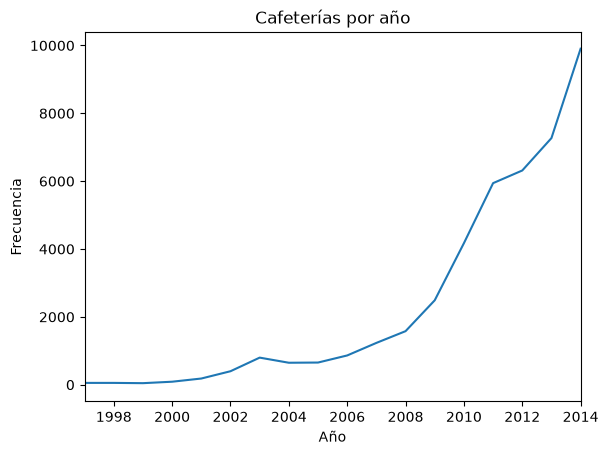

In [18]:
# ) Genera una tabla de frecuencias para la variable 'yearOfStart' y visualízala por año.
#• Ordena por año.
#• Dibuja una gráfica de línea de 1997 a 2014. <= Pista: plt.xlim()
frecuencias = cafeteria["Year of Start"].value_counts().sort_index()
años = frecuencias.reset_index()
años.columns = ["Años", "Frecuencias"]
plt.plot(años["Años"], años["Frecuencias"])
plt.xlabel("Año")
plt.ylabel("Frecuencia")
plt.xlim(1997,2014)
plt.title("Cafeterías por año")

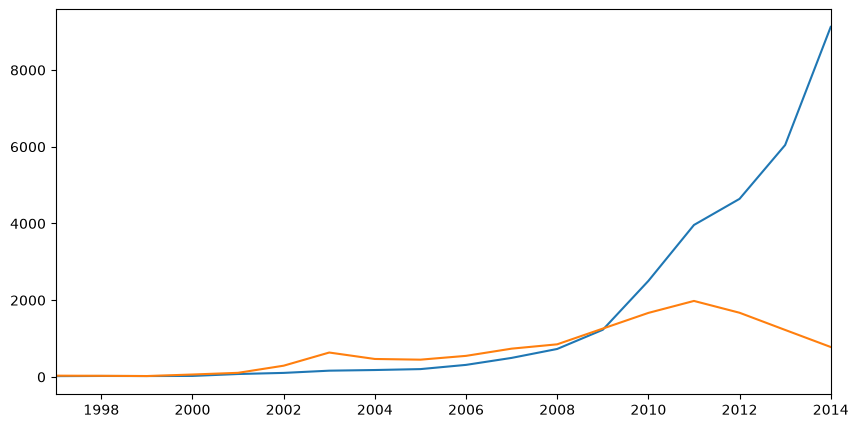

2

In [31]:
#2) Divide los datos por el estado actual del negocio ('In' o 'Out'). Después, visualiza la tendencia annual de las
#frecuencias de la variable 'yearOfStart'.
#• Ordena por año.
#• Dibuja dos gráficas de líneas superpuestas de 1997 a 2014.
#• Usa el objeto 'figure

cafeteria_in = cafeteria.loc[cafeteria["Current State"] == "In", "Year of Start"].value_counts().sort_index()
cafeteria_out = cafeteria.loc[cafeteria["Current State"] == "Out", "Year of Start"].value_counts().sort_index()

plt.figure(figsize=(10,5))
plt.plot(cafeteria_in.index, cafeteria_in.values, label = "In")
plt.plot(cafeteria_out.index, cafeteria_out.values, label="Out")
plt.xlim(1997,2014)
plt.show()
np.ndim(cafeteria)

## 3) A partir de los resultados de 1) y 2), ¿cómo describirías la tendencia en general?
###  desde el 2008 en adelante, la cantidad de cafeterias IN han aumentado significativamente en comparació de las Out que se mantienen frente al mismo margen en promedio, independientemente del tiempo

# 5. ¿Cuál es la sintaxis correcta para crear un arreglo de NumPy?
## ① np.createArray([1, 2, 3, 4, 5])
## ② np.array([1, 2, 3, 4, 5])
## ③ np.object([1, 2, 3, 4, 5])
### Desición: 2

# 6. ¿Cuál de las siguientes opciones es un arreglo de dos dimensiones?
## ① 42
## ② ([1, 2, 3], [4, 5, 6])
## ③ [1, 2,
### Decisión: 2

# 7. ¿Cuál es la sintaxis correcta para comprobar el número de dimensiones de un arreglo?
## ① np.dim()
## ② np.ndim()
## ③ np.ndim
## ④ np.dim
### Desición: 2

# 8. ¿Cuál es la sintaxis correcta para imprimir el primer elemento de un arreglo?
## ① print(myArr[0])
## ② print(myArr,1)
## ③ print(myArr[1])
### Desición: 1

# 9. ¿Cuál es la sintaxis correcta para imprimir el número 8 de la siguiente matriz?
## arr = np.array([[1,2,3,4,5], [6,7,8,9,10]])
## ① print(arr[3, 0])
## ② print(arr[7, 2])
## ③ print(arr[1, 2])
### Desición: 3

# 10. ¿Cuál es la sintaxis correcta para imprimir los números [3, 4, 5] de la siguiente matriz?
## arr = np.array([1,2,3,4,5,6,7])
## ① print(arr[2:4])
## ② print(arr[2:5])
## ③ print(arr[2:6])
## ④ print(arr[3:6])
### Desición: 2

# 11. ¿Cuál es el método correcto para unir dos o más arreglos?
## ① array_join()
## ② concatenate()
## ③ join()
### Desición: 2

# 12. ¿Cuál es la sintaxis correcta para devolver el índice de todos los elementos que tienen el valor 4 de ## la siguiente matriz?
## arr = np.array([1,4,3,4,5,4,4])
## ① arr.search(4)
## ② arr.where()
## ③ np.where(arr==4)
### Desición: 3


# 13. Cuando se utiliza el módulo random de NumPy, ¿cómo se puede devolver un número aleatorio entre 0 y 100?
## ① random.rand(100)
## ② random.rand()
## ③ random.randint(100)
### Desición: 3

# 14. Cuando se utiliza el módulo random de NumPy, ¿cómo se puede devolver una Distribución Normal de Datos ## con
## 1000 números, concentrados alrededor del número 50 y con una desviación estándar de 0.2?
## ① random.normal(size=1000, loc=50, scale=0.2)
## ② random.normal(size=1000, mean=50, deviation=0.2)
## ③ random.normal(size=1000, normal=50, s=0.1)
### Desición: 1

# 15. ¿Cuál es la sintaxis correcta para sumar matemáticamente los números de arr1 a los números de arr2?
## ① np.add(arr1, arr2)
## ② np.append(arr1, arr2)
## ③ sum(arr1, arr2)
### Desición: 1

# 16. ¿Cuál es la sintaxis correcta para restar los números de arr1 de los números de arr2?
## ① np.min(arr1, arr2)
## ② np.minus(arr1, arr2)
## ③ np.sub(arr1, arr2)
## ④ np.substract(arr1, arr2)
### Desición: 4

# 17. ¿Cuál es el método correcto para redondear decimales en NumPy?
## ① np.fix()
## ② np.trunc()
## ③ Las otras 3 opciones son métodos válidos en NumPy
## ④ np.around()
### Desición: 3

# 18. ¿Cuál sería la respuesta de esta suma acumulativa en NumPy?
## arr = np.array([1,2,3])
## print(np.cumsum(arr))
## ① [3, 6, 9]
## ② [6]
## ③ [9]
## ④ [1 3 6]
### Desición: 4

# 19. ¿Cuál es la sintaxis correcta para crear una Series de pandas a partir de una lista?
## ① pd.Series(mylist)
## ② pd.createSeries(mylist)
## ③ pd.getSeries(mylist)
### Desición: 1